# Klasifikasi Penyakit Kulit Menular dengan CNN untuk Skrining Awal

**Ujian Tengah Semester — Deep Learning**

| | |
|---|---|
| **Nama** | Christian Toga Raja Pasaribu |
| **NIM** | 102042330089 |

## 1. Identitas & Judul

Notebook ini berisi analisis kasus bisnis, penentuan pendekatan Deep Learning, serta rancangan dan evaluasi CNN sederhana untuk skrining awal penyakit kulit menular.

Capaian yang dituju:
- **[PLO01-CLO02]** Menganalisis permasalahan berbasis data dan menentukan model DL yang sesuai (Bagian 2, 4, 5).
- **[PLO02-CLO01]** Merancang dan mengevaluasi model DL sederhana untuk kebutuhan organisasi (Bagian 6 sampai 12).

## 2. Latar Belakang & Problem Bisnis

### Latar belakang
Cacar air (*chickenpox*), campak (*measles*), dan cacar monyet (*monkeypox/mpox*) adalah penyakit menular yang gejalanya tampak di kulit. Campak sangat mudah menular, sedangkan mpox pernah ditetapkan WHO sebagai darurat kesehatan global pada 2022. Semakin cepat kasus dicurigai, semakin cepat pasien dapat dirujuk dan diisolasi.

Di lapangan, dokter spesialis kulit umumnya terpusat di kota besar. Puskesmas dan layanan telemedisin sering harus menilai lesi kulit tanpa spesialis, padahal ruam ketiga penyakit ini bisa tampak mirip.

### Problem bisnis
> Bagaimana membantu puskesmas dan layanan telemedisin memilah foto lesi kulit dengan cepat, agar kasus yang dicurigai menular segera diprioritaskan untuk diperiksa tenaga medis?

### Tujuan sistem
Sistem menerima satu foto kulit, lalu mengeluarkan salah satu dari empat kelas (Chickenpox, Measles, Monkeypox, Normal) beserta tingkat keyakinannya. Sistem adalah **alat bantu triase, bukan pengganti dokter**. Keputusan diagnosis tetap pada tenaga medis.

### Stakeholder & manfaat

| Stakeholder | Manfaat |
|---|---|
| Puskesmas | Antrean pemeriksaan bisa diprioritaskan walau tanpa dokter spesialis |
| Layanan telemedisin | Foto kiriman pasien tersaring lebih dulu sebelum konsultasi |
| Pasien | Kasus berisiko lebih cepat mendapat rujukan |
| Dinas kesehatan | Potensi tambahan sebagai sinyal awal kasus menular |

### Metrik keberhasilan
Kesalahan yang paling berbahaya adalah pasien sakit yang lolos (*false negative*), karena pasien bisa tidak diperiksa dan terus menularkan. Salah alarm hanya menambah satu pemeriksaan. Karena itu, **recall per kelas penyakit** menjadi metrik utama.

| Metrik | Target rancangan |
|---|---|
| Recall tiap kelas penyakit | setidaknya 0,80 |
| Macro F1-score | setidaknya 0,75 |

Target ini adalah acuan rancangan, bukan standar klinis.

## 3. Import Library & Konfigurasi

Seluruh seed, path, dan hyperparameter berada di satu cell. Notebook memakai kernel **Python (UTS DL)** dari `.venv`, dengan TensorFlow 2.10 agar GPU dapat dipakai di Windows. DLL CUDA dan cuDNN disimpan di dalam `.venv`, sehingga folder tersebut perlu dimasukkan ke `PATH` sebelum TensorFlow diimpor.

In [20]:
import hashlib, json, os, sys, zipfile
from pathlib import Path

# CUDA & cuDNN ada di dalam .venv; harus masuk PATH sebelum import tensorflow
CUDA_BIN = Path(sys.prefix) / "cuda" / "bin"
if CUDA_BIN.exists():
    os.environ["PATH"] = str(CUDA_BIN) + os.pathsep + os.environ["PATH"]
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from PIL import Image
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import callbacks, layers, models, optimizers

tf.get_logger().setLevel("ERROR")

# Konfigurasi
SEED = 42
PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw"
DATA_DIR = RAW_DIR / "Dataset_Gabungan"
MODEL_PATH = PROJECT_DIR / "best_model.keras"
HISTORY_PATH = PROJECT_DIR / "history.json"
KAGGLE_SLUG = "gupiii/infectious-skin-disease-dataset"

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 15
LR = 0.001
DROPOUT = 0.5
AMBANG_MIRIP = 0.95  # korelasi piksel minimum agar dua foto dianggap foto yang sama

tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

# VRAM dipakai bertahap, tidak langsung penuh
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)


def tabel(df, index=False, presisi=3):
    """Tampilkan tabel hitam-putih tanpa warna."""
    gaya = "border:1px solid black;background-color:white;color:black;padding:4px 10px;text-align:left;"
    s = (df.style.format(precision=presisi)
         .set_table_attributes('style="border-collapse:collapse"')
         .set_table_styles([{"selector": "th", "props": gaya}, {"selector": "td", "props": gaya}]))
    display(s if index else s.hide(axis="index"))


print("TensorFlow:", tf.__version__)
print("GPU terdeteksi:", gpus)

TensorFlow: 2.10.1
GPU terdeteksi: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Temuan:** TensorFlow 2.10.1 mendeteksi satu GPU (NVIDIA RTX 4060), sehingga training dapat berjalan di GPU.

In [21]:
# Pakai data lokal jika sudah ada; jika belum, unduh dari Kaggle dengan token di .env
if not DATA_DIR.exists():
    baris = (PROJECT_DIR / ".env").read_text().strip().splitlines()
    token = next(b.split("=", 1)[1].strip().strip("\"'") for b in baris if b.lower().strip().startswith("kaggle_api"))
    url = f"https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_SLUG}"
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    arsip = RAW_DIR / "dataset.zip"
    with requests.get(url, headers={"Authorization": f"Bearer {token}"}, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(arsip, "wb") as f:
            for potongan in r.iter_content(1 << 20):
                f.write(potongan)
    with zipfile.ZipFile(arsip) as z:
        z.extractall(RAW_DIR)
    arsip.unlink()

print("Folder data:", DATA_DIR.relative_to(PROJECT_DIR))
print("Isi data/raw:", sorted(p.name for p in RAW_DIR.iterdir()))

Folder data: data\raw\Dataset_Gabungan
Isi data/raw: ['Dataset_1', 'Dataset_2', 'Dataset_Gabungan']


**Temuan:** Dataset tersedia secara lokal di `data/raw`. Jika folder tersebut belum ada, cell di atas mengunduhnya dari Kaggle memakai token pada `.env`. Token tidak pernah ditampilkan di notebook.

## 4. Analisis Data

Sumber data: [Infectious Skin Disease Dataset](https://www.kaggle.com/datasets/gupiii/infectious-skin-disease-dataset) di Kaggle. Nama folder menjadi label, sehingga tidak perlu pelabelan manual.

### 4.1 Struktur dataset

In [22]:
baris = []
for sumber in sorted(p for p in RAW_DIR.iterdir() if p.is_dir()):
    hitung = {k.name: len(list(k.iterdir())) for k in sorted(sumber.iterdir())}
    baris.append({"Folder": sumber.name, **hitung, "Total": sum(hitung.values())})
struktur = pd.DataFrame(baris)
total = pd.DataFrame([{"Folder": "Semua folder", **struktur.drop(columns="Folder").sum().to_dict()}])
tabel(pd.concat([struktur, total], ignore_index=True))

# Bukti Dataset_Gabungan = Dataset_1 + Dataset_2
md5_folder = {s: {hashlib.md5(p.read_bytes()).hexdigest() for p in (RAW_DIR / s).glob("*/*")}
              for s in ["Dataset_1", "Dataset_2", "Dataset_Gabungan"]}
print("Isi Dataset_1 + Dataset_2 sama dengan Dataset_Gabungan:",
      (md5_folder["Dataset_1"] | md5_folder["Dataset_2"]) == md5_folder["Dataset_Gabungan"])

Folder,Chickenpox,Measles,Monkeypox,Normal,Total
Dataset_1,100,80,264,215,659
Dataset_2,107,91,279,293,770
Dataset_Gabungan,207,171,543,508,1429
Semua folder,414,342,1086,1016,2858


Isi Dataset_1 + Dataset_2 sama dengan Dataset_Gabungan: True


**Temuan:** Angka 2.858 gambar pada halaman dataset adalah total ketiga folder. `Dataset_Gabungan` (1.429 gambar) isinya sama dengan `Dataset_1` + `Dataset_2`, jadi 2.858 menghitung setiap gambar dua kali. Notebook ini hanya memakai **`Dataset_Gabungan`**.

### 4.2 Jumlah gambar per kelas

Kelas,Jumlah,Persen (%)
Chickenpox,207,14.5
Measles,171,12.0
Monkeypox,543,38.0
Normal,508,35.5


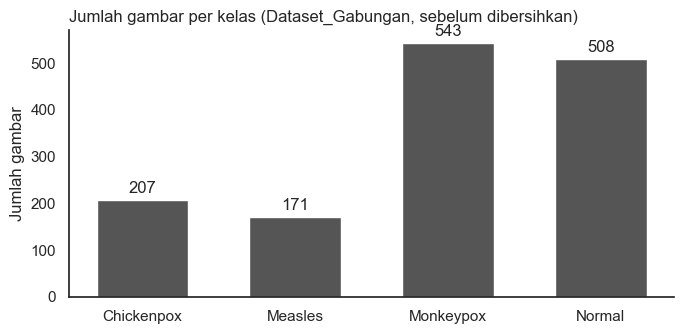

In [23]:
df = pd.DataFrame([{"path": str(p), "nama": p.name, "kelas": p.parent.name}
                   for p in sorted(DATA_DIR.glob("*/*"))])
KELAS = sorted(df["kelas"].unique())

jumlah = df["kelas"].value_counts().reindex(KELAS)
tabel(pd.DataFrame({"Kelas": KELAS, "Jumlah": jumlah.values,
                    "Persen (%)": (jumlah.values / len(df) * 100).round(1)}), presisi=1)

fig, ax = plt.subplots(figsize=(7, 3.5))
batang = ax.bar(KELAS, jumlah.values, color="#555555", width=0.6)
ax.bar_label(batang, padding=3)
ax.set_title("Jumlah gambar per kelas (Dataset_Gabungan, sebelum dibersihkan)", loc="left")
ax.set_ylabel("Jumlah gambar")
plt.tight_layout()
plt.show()

**Temuan:** Data tidak seimbang. Monkeypox (38,0%) dan Normal (35,5%) mendominasi, sedangkan Chickenpox (14,5%) dan Measles (12,0%) jauh lebih sedikit. Tanpa penanganan, model cenderung mengabaikan dua kelas kecil, sehingga diperlukan *class weight*.

### 4.3 Contoh gambar tiap kelas

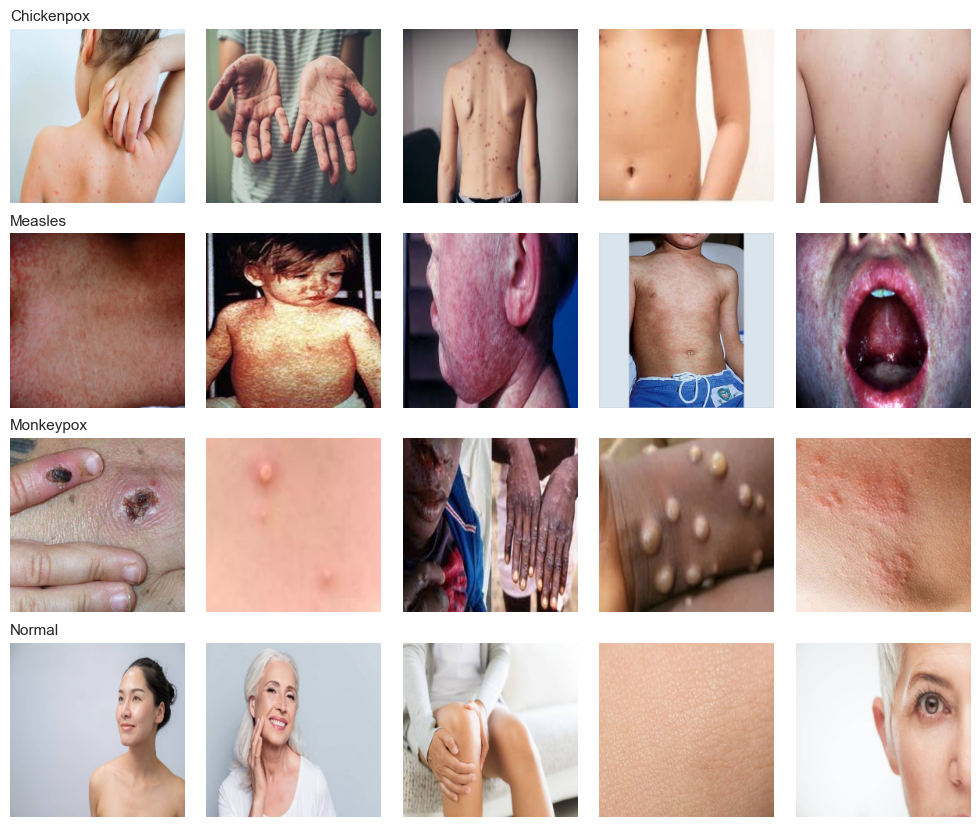

In [24]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(KELAS), 5, figsize=(10, 8.4))
for b, k in enumerate(KELAS):
    contoh = rng.choice(df.loc[df["kelas"] == k, "path"].values, 5, replace=False)
    for c, p in enumerate(contoh):
        axes[b, c].imshow(Image.open(p).convert("RGB"))
        axes[b, c].axis("off")
    axes[b, 0].set_title(k, loc="left", fontsize=11)
plt.tight_layout()
plt.show()

**Temuan:** Label foto terlihat wajar, tetapi ada tiga hal yang perlu diwaspadai:
- **Kemiripan antarkelas**: bintil dan ruam pada Chickenpox, Monkeypox, dan Measles bisa tampak mirip, sehingga berpotensi tertukar.
- **Latar foto berbeda antarkelas**: banyak foto Normal berupa potret bergaya foto stok dengan latar bersih, sedangkan foto penyakit lebih bergaya klinis. Model bisa belajar dari gaya foto, bukan dari kondisi kulit.
- **Watermark**: sebagian foto Chickenpox memuat watermark *gettyimages*, yang dapat menjadi petunjuk palsu bagi model.

### 4.4 Ukuran gambar & file rusak

In [25]:
info, rusak = [], []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            im.load()
            info.append({"Ukuran": f"{im.width} x {im.height}", "Mode": im.mode, "Format": im.format})
    except Exception as e:
        rusak.append((p, str(e)))

print("File rusak/tidak terbaca:", len(rusak))
info = pd.DataFrame(info)
tabel(info.value_counts().rename("Jumlah").reset_index())

File rusak/tidak terbaca: 0


Ukuran,Mode,Format,Jumlah
224 x 224,RGB,PNG,770
256 x 256,RGB,JPEG,659


**Temuan:** Tidak ada file rusak dan semua gambar berformat RGB. Hanya ada dua ukuran: 256 x 256 (JPEG, 659 gambar dari `Dataset_1`) dan 224 x 224 (PNG, 770 gambar dari `Dataset_2`). Semua gambar akan diseragamkan menjadi 128 x 128.

### 4.5 Duplikat & kebocoran data

Dua pemeriksaan dilakukan agar foto yang sama tidak masuk ke train dan test sekaligus:
1. **Duplikat persis**: isi file sama (hash MD5).
2. **Foto yang sama dengan format berbeda**: gambar dikecilkan ke 64 x 64 abu-abu, lalu dihitung korelasi pikselnya, termasuk versi cermin. Korelasi minimal 0,95 dianggap foto yang sama.

Foto berlabel ganda:


nama,kelas
ds1_ChickenPox_88.jpg,Chickenpox
ds2_chickenpox94.png,Chickenpox
ds1_MonkeyPox_82.jpg,Monkeypox
ds2_monkeypox84.png,Monkeypox


Tahap,Jumlah
Dataset_Gabungan,1429
Setelah buang duplikat persis,1419
Foto berbeda (setelah gabung format berbeda),749
Setelah buang label ganda,748


Sebaran korelasi tertinggi tiap gambar:


Korelasi tertinggi,Jumlah gambar
"di bawah 0,80",101
"0,80 - 0,90",5
"0,90 - 0,95",1
"0,95 - 0,98",0
"0,98 ke atas",1312


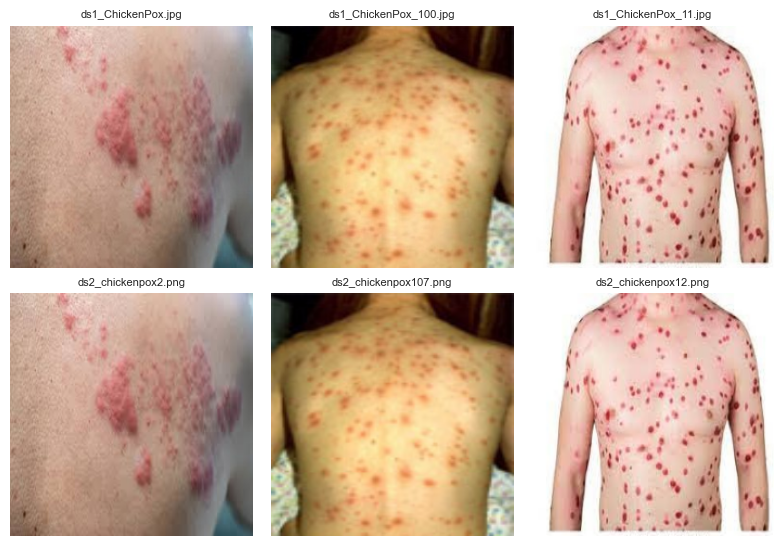

Kelas,Sebelum,Sesudah,Persen sesudah (%)
Chickenpox,207,101,13.5
Measles,171,87,11.6
Monkeypox,543,271,36.2
Normal,508,289,38.6


Rasio kelas terbesar : terkecil = 3.32


In [26]:
df["md5"] = df["path"].map(lambda p: hashlib.md5(Path(p).read_bytes()).hexdigest())
df_unik = df.drop_duplicates("md5").reset_index(drop=True)

A = np.stack([np.asarray(Image.open(p).convert("L").resize((64, 64), Image.BILINEAR), dtype=np.float32)
              for p in df_unik["path"]])


def normalisasi(a):
    v = a.reshape(len(a), -1)
    v = v - v.mean(axis=1, keepdims=True)
    return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-8)


X = normalisasi(A)
S = X @ X.T
for B in (A[:, :, ::-1], A[:, ::-1, :], A[:, ::-1, ::-1]):  # cermin horizontal, vertikal, keduanya
    S = np.maximum(S, X @ normalisasi(B).T)
S = np.maximum(S, S.T)
np.fill_diagonal(S, -1)

n_grup, df_unik["grup"] = connected_components(csr_matrix(S >= AMBANG_MIRIP), directed=False)

# Foto yang sama tetapi berlabel berbeda dibuang karena labelnya tidak bisa dipercaya
per_grup = df_unik.groupby("grup")["kelas"].nunique()
grup_konflik = per_grup[per_grup > 1].index
konflik = df_unik[df_unik["grup"].isin(grup_konflik)]
print("Foto berlabel ganda:")
tabel(konflik[["nama", "kelas"]])

# Satu foto = satu sampel
df_bersih = (df_unik[~df_unik["grup"].isin(grup_konflik)].sort_values("nama")
             .drop_duplicates("grup").sort_values(["kelas", "nama"]).reset_index(drop=True))

tabel(pd.DataFrame({"Tahap": ["Dataset_Gabungan", "Setelah buang duplikat persis",
                              "Foto berbeda (setelah gabung format berbeda)", "Setelah buang label ganda"],
                    "Jumlah": [len(df), len(df_unik), n_grup, len(df_bersih)]}))

print("Sebaran korelasi tertinggi tiap gambar:")
bin_kor = [-1, 0.80, 0.90, 0.95, 0.98, 1.01]
lab_kor = ["di bawah 0,80", "0,80 - 0,90", "0,90 - 0,95", "0,95 - 0,98", "0,98 ke atas"]
tabel(pd.DataFrame({"Korelasi tertinggi": lab_kor, "Jumlah gambar": np.histogram(S.max(axis=1), bins=bin_kor)[0]}))

# Contoh foto yang sama dengan format berbeda
contoh_grup = [g for g, v in df_unik.groupby("grup") if len(v) == 2 and v["kelas"].nunique() == 1
               and {n[:3] for n in v["nama"]} == {"ds1", "ds2"}][:3]
fig, axes = plt.subplots(2, 3, figsize=(8, 5.6))
for c, g in enumerate(contoh_grup):
    for b, (_, r) in enumerate(df_unik[df_unik["grup"] == g].sort_values("nama").iterrows()):
        axes[b, c].imshow(Image.open(r["path"]).convert("RGB"))
        axes[b, c].set_title(f"{r['nama']}", fontsize=8)
        axes[b, c].axis("off")
plt.tight_layout()
plt.show()

jumlah_bersih = df_bersih["kelas"].value_counts().reindex(KELAS)
tabel(pd.DataFrame({"Kelas": KELAS, "Sebelum": jumlah.values, "Sesudah": jumlah_bersih.values,
                    "Persen sesudah (%)": (jumlah_bersih.values / len(df_bersih) * 100).round(1)}), presisi=1)
print("Rasio kelas terbesar : terkecil =", round(jumlah_bersih.max() / jumlah_bersih.min(), 2))

**Temuan:** Ini temuan terpenting pada analisis data:
- Hanya **10 gambar** yang duplikat persis, tetapi `Dataset_1` dan `Dataset_2` ternyata banyak berisi **foto yang sama** dalam format berbeda (JPEG 256 x 256 dan PNG 224 x 224), seperti terlihat pada contoh gambar.
- Sebaran korelasi terpisah sangat jelas: 1.312 gambar memiliki pasangan dengan korelasi 0,98 ke atas, dan hampir semua sisanya di bawah 0,90. Tidak ada gambar pada rentang 0,95 sampai 0,98, sehingga ambang 0,95 aman.
- Satu foto muncul sebagai **Chickenpox sekaligus Monkeypox**. Karena labelnya tidak dapat dipercaya, foto ini dibuang.
- Jumlah foto yang benar-benar berbeda adalah **748**, bukan 1.429. Tanpa pembersihan, foto yang sama akan masuk ke train dan test, sehingga akurasi terlihat tinggi padahal model hanya mengingat foto.

Rasio kelas terbesar dan terkecil setelah pembersihan adalah 3,32 banding 1.

### Ringkasan temuan analisis data

| Aspek | Temuan | Tindakan |
|---|---|---|
| Jumlah data | 748 foto berbeda dari 1.429 gambar | Satu foto dipakai sebagai satu sampel |
| Kebocoran | Foto yang sama muncul dalam dua format | Duplikat dibuang sebelum split |
| Label | Satu foto berlabel ganda | Dibuang |
| Keseimbangan | Rasio 3,32 banding 1 | *Class weight* dan split *stratified* |
| Kualitas | Tidak ada file rusak | Tidak perlu tindakan |
| Bias foto | Latar foto dan watermark berbeda antarkelas | Dicatat sebagai risiko dan diperiksa saat analisis kesalahan |

## 5. Penentuan Pendekatan Deep Learning

### Kenapa klasifikasi gambar multi-kelas?
Setiap foto memiliki satu label dari empat kelas, dan output yang dibutuhkan adalah satu kategori.
- **Bukan deteksi objek**: dataset tidak memiliki anotasi *bounding box*, dan triase cukup membutuhkan kategori per foto.
- **Bukan regresi**: targetnya kategori, bukan nilai kontinu.

Karena itu, output model memakai `Dense` dengan aktivasi **softmax** dan loss `sparse_categorical_crossentropy`.

### Kenapa CNN, bukan MLP?

| Aspek | MLP | CNN |
|---|---|---|
| Cara membaca gambar | Piksel diratakan, hubungan antartetangga hilang | Filter membaca area lokal |
| Fitur lesi di posisi berbeda | Harus dipelajari ulang tiap posisi | Filter yang sama dipakai di seluruh gambar |
| Jumlah parameter untuk input 128 x 128 x 3 | Sekitar 6,3 juta pada satu layer 128 neuron | Jauh lebih sedikit |

Lesi kulit dikenali dari pola spasial: bentuk bintil, tepi, tekstur, dan sebaran. Pola seperti ini cocok dengan CNN. Pada data sekecil ini, parameter yang lebih sedikit juga menurunkan risiko *overfitting*.

### Kenapa tanpa pre-trained model?
Tujuan UTS adalah merancang dan mengevaluasi model sederhana, sehingga CNN dibangun dari nol agar setiap layer dapat dijelaskan dan dipertanggungjawabkan. *Transfer learning* (MobileNetV2 atau EfficientNetB0) biasanya lebih akurat pada data kecil, sehingga dicatat sebagai pengembangan selanjutnya.

## 6. Preprocessing

### 6.1 Split data 70/15/15
Split dilakukan secara *stratified* dengan seed tetap. Karena tiap baris pada `df_bersih` adalah foto yang berbeda, foto yang sama tidak dapat muncul di dua subset.

In [27]:
label_ke_id = {k: i for i, k in enumerate(KELAS)}
df_bersih["label"] = df_bersih["kelas"].map(label_ke_id)

train_df, sisa_df = train_test_split(df_bersih, test_size=0.30, stratify=df_bersih["label"], random_state=SEED)
val_df, test_df = train_test_split(sisa_df, test_size=0.50, stratify=sisa_df["label"], random_state=SEED)

# Pastikan tidak ada kebocoran antar-subset
assert not (set(train_df["grup"]) & set(val_df["grup"]))
assert not (set(train_df["grup"]) & set(test_df["grup"]))
assert not (set(val_df["grup"]) & set(test_df["grup"]))

ringkas = pd.DataFrame({n: d["kelas"].value_counts().reindex(KELAS)
                        for n, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]})
ringkas.loc["Total"] = ringkas.sum()
tabel(ringkas.rename_axis("Kelas").reset_index())
print("Proporsi:", {n: round(len(d) / len(df_bersih), 3) for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]})

Kelas,Train,Val,Test
Chickenpox,71,15,15
Measles,61,13,13
Monkeypox,189,41,41
Normal,202,43,44
Total,523,112,113


Proporsi: {'train': 0.699, 'val': 0.15, 'test': 0.151}


**Temuan:** Data terbagi menjadi 523 train, 112 validasi, dan 113 test (69,9% / 15,0% / 15,1%), dengan proporsi kelas yang terjaga. Pemeriksaan `assert` memastikan tidak ada foto yang sama di dua subset. Data test kelas kecil hanya 15 (Chickenpox) dan 13 (Measles), sehingga satu kesalahan prediksi mengubah recall kelas tersebut sekitar 7 sampai 8 poin persen.

### 6.2 Pipeline data
Gambar dibaca, di-*resize* ke 128 x 128, disimpan di `cache`, lalu disiapkan lebih dulu dengan `prefetch` agar GPU tidak menunggu data. *Rescaling* 1/255 dan augmentasi diletakkan di dalam model (Bagian 7), sehingga otomatis ikut terpakai saat prediksi dan augmentasi hanya aktif saat training.

In [28]:
AUTOTUNE = tf.data.AUTOTUNE


def baca_gambar(path, label):
    gambar = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(gambar, IMG_SIZE), label


def buat_dataset(data, acak=False):
    ds = tf.data.Dataset.from_tensor_slices((data["path"].values, data["label"].values))
    ds = ds.map(baca_gambar, num_parallel_calls=AUTOTUNE).cache()
    if acak:
        ds = ds.shuffle(len(data), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = buat_dataset(train_df, acak=True)
val_ds = buat_dataset(val_df)
test_ds = buat_dataset(test_df)

gambar_contoh, label_contoh = next(iter(train_ds))
print("Bentuk satu batch:", gambar_contoh.shape, "| rentang piksel:",
      float(tf.reduce_min(gambar_contoh)), "-", float(tf.reduce_max(gambar_contoh)))

Bentuk satu batch: (32, 128, 128, 3) | rentang piksel: 0.0 - 255.0


**Temuan:** Satu batch berbentuk 32 gambar ukuran 128 x 128 x 3 dengan rentang piksel 0 sampai 255. Rentang tersebut sesuai rancangan, karena *rescaling* ke 0 sampai 1 dilakukan oleh layer pertama model.

### 6.3 Augmentasi
Flip, rotasi, dan zoom kecil membuat variasi posisi foto tanpa mengubah jenis lesi. Teknik ini membantu mengurangi *overfitting* pada data kecil.

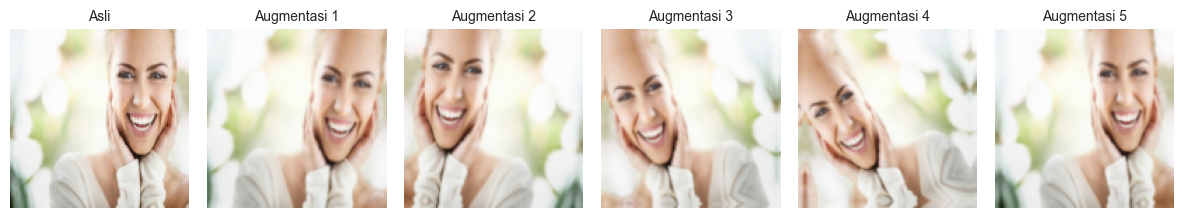

In [29]:
augmentasi = models.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.1, seed=SEED),
    layers.RandomZoom(0.1, seed=SEED),
], name="augmentasi")

gambar = gambar_contoh[0][tf.newaxis]
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
axes[0].imshow(gambar[0].numpy().astype("uint8"))
axes[0].set_title("Asli", fontsize=10)
axes[0].axis("off")
for i in range(1, 6):
    hasil = augmentasi(gambar, training=True)
    axes[i].imshow(np.clip(hasil[0].numpy(), 0, 255).astype("uint8"))
    axes[i].set_title(f"Augmentasi {i}", fontsize=10)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

**Temuan:** Gambar hasil augmentasi masih jelas dan objeknya tetap utuh, sehingga besar flip, rotasi, dan zoom sudah wajar. Sisi kosong akibat rotasi terisi oleh pantulan gambar, yang masih dapat diterima pada tingkat rotasi kecil ini.

### 6.4 Class weight
Bobot kelas membuat kesalahan pada kelas kecil lebih berpengaruh terhadap loss, sehingga model tidak hanya mengejar kelas mayoritas.

In [30]:
bobot = compute_class_weight("balanced", classes=np.arange(len(KELAS)), y=train_df["label"])
class_weight = dict(enumerate(bobot))
tabel(pd.DataFrame({"Kelas": KELAS, "Jumlah train": ringkas.loc[KELAS, "Train"].values, "Class weight": bobot}))

Kelas,Jumlah train,Class weight
Chickenpox,71,1.842
Measles,61,2.143
Monkeypox,189,0.692
Normal,202,0.647


**Temuan:** Measles (2,143) dan Chickenpox (1,842) mendapat bobot paling besar, sedangkan Monkeypox (0,692) dan Normal (0,647) lebih kecil. Kesalahan pada satu foto Measles kini berbobot lebih dari tiga kali kesalahan pada satu foto Normal.

## 7. Rancangan Arsitektur CNN

Arsitektur memakai tiga blok konvolusi dengan jumlah filter yang meningkat. Setelah blok terakhir digunakan `GlobalAveragePooling2D`, bukan `Flatten`, agar jumlah parameter jauh lebih kecil dan risiko *overfitting* pada dataset kecil ini berkurang.

In [31]:
model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    layers.Rescaling(1.0 / 255, name="rescaling"),
    augmentasi,
    layers.Conv2D(32, 3, activation="relu", name="conv_1"),
    layers.MaxPooling2D(name="pool_1"),
    layers.Conv2D(64, 3, activation="relu", name="conv_2"),
    layers.MaxPooling2D(name="pool_2"),
    layers.Conv2D(128, 3, activation="relu", name="conv_3"),
    layers.MaxPooling2D(name="pool_3"),
    layers.GlobalAveragePooling2D(name="gap"),
    layers.Dense(128, activation="relu", name="dense"),
    layers.Dropout(DROPOUT, seed=SEED, name="dropout"),
    layers.Dense(len(KELAS), activation="softmax", name="output"),
], name="cnn_kulit")

model.summary()

Model: "cnn_kulit"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 128, 128, 3)       0         
                                                                 
 augmentasi (Sequential)     (None, 128, 128, 3)       0         
                                                                 
 conv_1 (Conv2D)             (None, 126, 126, 32)      896       
                                                                 
 pool_1 (MaxPooling2D)       (None, 63, 63, 32)        0         
                                                                 
 conv_2 (Conv2D)             (None, 61, 61, 64)        18496     
                                                                 
 pool_2 (MaxPooling2D)       (None, 30, 30, 64)        0         
                                                                 
 conv_3 (Conv2D)             (None, 28, 28, 128)       73

**Temuan:** Model memiliki **110.276 parameter** yang semuanya dapat dilatih. Peta fitur terakhir berukuran 14 x 14 x 128. Jika memakai `Flatten`, layer `Dense` saja akan membutuhkan 3.211.392 parameter, sedangkan dengan `GlobalAveragePooling2D` hanya 16.512. Pilihan ini penting karena data train hanya 523 foto.

| Layer | Fungsi | Parameter |
|---|---|---|
| `Rescaling` | Mengubah piksel 0-255 menjadi 0-1 agar training stabil | 0 |
| `augmentasi` | Flip, rotasi, dan zoom acak, hanya aktif saat training | 0 |
| `conv_1` (32 filter) | Menangkap fitur dasar seperti tepi dan warna | 896 |
| `conv_2` (64 filter) | Menggabungkan fitur dasar menjadi tekstur | 18.496 |
| `conv_3` (128 filter) | Menangkap pola lesi yang lebih kompleks | 73.856 |
| `MaxPooling2D` | Memperkecil ukuran peta fitur setengahnya | 0 |
| `GlobalAveragePooling2D` | Merata-ratakan tiap peta fitur menjadi satu angka | 0 |
| `Dense` (128) | Menggabungkan fitur untuk keputusan kelas | 16.512 |
| `Dropout` (0,5) | Mematikan neuron acak saat training untuk mengurangi *overfitting* | 0 |
| `output` (softmax) | Menghasilkan probabilitas keempat kelas | 516 |

## 8. Training

Konfigurasi: Adam (learning rate 0,001), loss `sparse_categorical_crossentropy`, metrik accuracy, maksimal 15 epoch.

| Callback | Fungsi |
|---|---|
| `EarlyStopping` (patience 3) | Menghentikan training saat `val_loss` tidak membaik |
| `ReduceLROnPlateau` (factor 0,5, patience 2) | Menurunkan learning rate saat `val_loss` stagnan |
| `ModelCheckpoint` | Menyimpan bobot terbaik, termasuk jika training berjalan sampai epoch terakhir |

In [32]:
model.compile(optimizer=optimizers.Adam(learning_rate=LR),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

daftar_callback = [
    callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    callbacks.ModelCheckpoint(str(MODEL_PATH), monitor="val_loss", save_best_only=True, verbose=1),
]
print("Model siap dilatih. Optimizer:", type(model.optimizer).__name__, "| LR:", float(model.optimizer.learning_rate))

Model siap dilatih. Optimizer: Adam | LR: 0.0010000000474974513


In [14]:
# CELL TRAINING: dijalankan oleh user di GPU
assert gpus, "GPU tidak terdeteksi. Pastikan kernel 'Python (UTS DL)' yang dipakai."

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=daftar_callback,
)

Epoch 1/15
17/17 [==============================] - ETA: 0s - loss: 1.3930 - accuracy: 0.2811
Epoch 1: val_loss improved from inf to 1.38514, saving model to c:\Users\ASUS\Documents\Coolyeahhh\KULIAH SEMESTER 7\DL\UTS DL\best_model.keras
17/17 [==============================] - 16s 319ms/step - loss: 1.3930 - accuracy: 0.2811 - val_loss: 1.3851 - val_accuracy: 0.3571 - lr: 0.0010
Epoch 2/15
17/17 [==============================] - ETA: 0s - loss: 1.3844 - accuracy: 0.2715
Epoch 2: val_loss improved from 1.38514 to 1.35792, saving model to c:\Users\ASUS\Documents\Coolyeahhh\KULIAH SEMESTER 7\DL\UTS DL\best_model.keras
17/17 [==============================] - 4s 254ms/step - loss: 1.3844 - accuracy: 0.2715 - val_loss: 1.3579 - val_accuracy: 0.4286 - lr: 0.0010
Epoch 3/15
17/17 [==============================] - ETA: 0s - loss: 1.3455 - accuracy: 0.4340
Epoch 3: val_loss improved from 1.35792 to 1.32191, saving model to c:\Users\ASUS\Documents\Coolyeahhh\KULIAH SEMESTER 7\DL\UTS DL\best_m

In [15]:
# Muat model terbaik dan simpan riwayat training
model = tf.keras.models.load_model(MODEL_PATH)
riwayat = {k: [float(x) for x in v] for k, v in history.history.items()}
HISTORY_PATH.write_text(json.dumps(riwayat, indent=2))

epoch_terbaik = int(np.argmin(riwayat["val_loss"])) + 1
print("Jumlah epoch berjalan:", len(riwayat["val_loss"]))
print("Epoch terbaik:", epoch_terbaik)
print("val_loss terbaik:", round(min(riwayat["val_loss"]), 4))
print("val_accuracy pada epoch terbaik:", round(riwayat["val_accuracy"][epoch_terbaik - 1], 4))

Jumlah epoch berjalan: 12
Epoch terbaik: 9
val_loss terbaik: 1.1838
val_accuracy pada epoch terbaik: 0.5268


**Temuan:** Training berhenti otomatis pada epoch 12 dari maksimal 15. Bobot terbaik berasal dari **epoch 9**, dengan `val_loss` 1,1838 dan `val_accuracy` 52,68%. Setiap epoch hanya memakan waktu sekitar 4 sampai 5 detik di GPU.

Akurasi validasi tersebut lebih baik daripada menebak kelas terbanyak (Normal, 43 dari 112 foto atau 38,4%), tetapi masih rendah untuk kebutuhan triase.

## 9. Evaluasi

Evaluasi akhir memakai data test, yaitu foto yang tidak pernah dilihat model saat training.

### 9.1 Kurva loss & accuracy

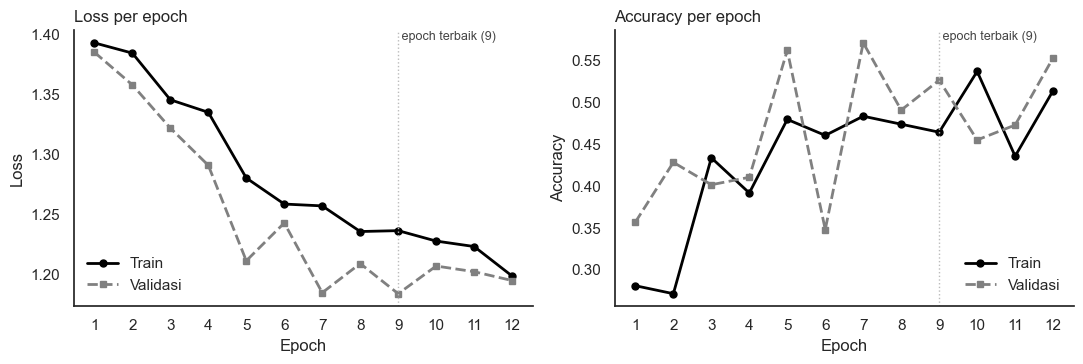

In [16]:
riwayat = json.loads(HISTORY_PATH.read_text())
epoch = np.arange(1, len(riwayat["loss"]) + 1)
terbaik = int(np.argmin(riwayat["val_loss"])) + 1

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, kunci, judul in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(epoch, riwayat[kunci], color="black", linewidth=2, marker="o", markersize=5, label="Train")
    ax.plot(epoch, riwayat[f"val_{kunci}"], color="#808080", linewidth=2, linestyle="--", marker="s", markersize=5, label="Validasi")
    ax.axvline(terbaik, color="#BBBBBB", linewidth=1, linestyle=":")
    ax.text(terbaik, ax.get_ylim()[1], f" epoch terbaik ({terbaik})", fontsize=9, va="top", color="#444444")
    ax.set_title(f"{judul} per epoch", loc="left")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(judul)
    ax.set_xticks(epoch)
    ax.legend(frameon=False, loc="lower right" if kunci == "accuracy" else "lower left")
plt.tight_layout()
plt.show()

**Temuan:**
- **Tidak terjadi *overfitting***. Kurva train dan validasi berjalan berdekatan, dan akurasi validasi pada epoch terbaik (52,68%) tidak lebih rendah daripada akurasi train (46,46%).
- **Model mengalami *underfitting***. Loss hanya turun dari sekitar 1,39 (setara tebakan acak untuk empat kelas) menjadi sekitar 1,20, dan akurasi train tidak melewati 54%.
- Kurva validasi naik turun (akurasi 34,8% sampai 57,1%) karena data validasi hanya 112 foto.
- Metrik train dihitung dengan augmentasi, *dropout*, dan *class weight* yang aktif, sedangkan validasi tidak. Karena itu, metrik validasi dapat terlihat lebih baik daripada train.

### 9.2 Evaluasi pada data test

In [17]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
y_prob = model.predict(test_ds, verbose=0)
y_true = test_df["label"].values
y_pred = y_prob.argmax(axis=1)

kelas_terbanyak = test_df["label"].value_counts(normalize=True).max()
tabel(pd.DataFrame({"Metrik": ["Test loss", "Test accuracy", "Akurasi jika selalu menebak kelas terbanyak"],
                    "Nilai": [test_loss, test_acc, kelas_terbanyak]}), presisi=4)

Metrik,Nilai
Test loss,1.1570
Test accuracy,0.5752
Akurasi jika selalu menebak kelas terbanyak,0.3894


**Temuan:** Akurasi test adalah **57,52%** dengan loss 1,1570. Nilai ini lebih tinggi daripada menebak kelas terbanyak (38,94%) dan dekat dengan akurasi validasi (52,68%), sehingga model konsisten pada data baru. Namun, akurasi saja menyesatkan pada data tidak seimbang, sehingga hasil per kelas perlu dilihat.

### 9.3 Precision, recall, dan F1-score per kelas

In [18]:
laporan = pd.DataFrame(classification_report(y_true, y_pred, target_names=KELAS, output_dict=True, zero_division=0)).T
laporan = laporan.rename(columns={"precision": "Precision", "recall": "Recall", "f1-score": "F1-score", "support": "Jumlah"})
laporan.loc["accuracy", ["Precision", "Recall"]] = np.nan
laporan.loc["accuracy", "Jumlah"] = len(y_true)
laporan["Jumlah"] = laporan["Jumlah"].astype(int)
tabel(laporan.rename_axis("Kelas").reset_index())

penyakit = [k for k in KELAS if k != "Normal"]
tabel(pd.DataFrame({"Kelas penyakit": penyakit, "Recall": laporan.loc[penyakit, "Recall"].values,
                    "Target": 0.80, "Tercapai": ["Ya" if laporan.loc[k, "Recall"] >= 0.80 else "Tidak" for k in penyakit]}))

Kelas,Precision,Recall,F1-score,Jumlah
Chickenpox,0.000,0.000,0.000,15
Measles,0.000,0.000,0.000,13
Monkeypox,0.544,0.902,0.679,41
Normal,0.848,0.636,0.727,44
accuracy,nan,nan,0.575,113
macro avg,0.348,0.385,0.352,113
weighted avg,0.528,0.575,0.530,113


Kelas penyakit,Recall,Target,Tercapai
Chickenpox,0.000,0.800,Tidak
Measles,0.000,0.800,Tidak
Monkeypox,0.902,0.800,Ya


**Temuan:**
- **Kelas terbaik**: Normal (F1-score 0,727) dan Monkeypox (F1-score 0,679).
- **Kelas terburuk**: Chickenpox dan Measles, dengan precision, recall, dan F1-score **0**. Tidak satu pun foto kedua kelas ini dikenali dengan benar.
- Recall Monkeypox tinggi (0,902), tetapi precision-nya hanya 0,544, karena model terlalu sering menebak Monkeypox.
- **Target rancangan belum tercapai**. Hanya satu dari tiga kelas penyakit yang mencapai recall 0,80, dan macro F1-score 0,352 jauh di bawah target 0,75.

### 9.4 Confusion matrix

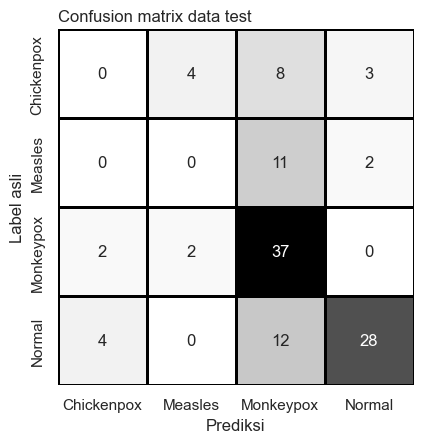

In [19]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(KELAS)))

fig, ax = plt.subplots(figsize=(5.6, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greys", cbar=False, linewidths=1, linecolor="black",
            xticklabels=KELAS, yticklabels=KELAS, square=True, ax=ax)
ax.set_title("Confusion matrix data test", loc="left")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label asli")
plt.tight_layout()
plt.show()

**Temuan:** Model menebak Monkeypox pada 68 dari 113 foto (60%). Sebanyak 11 dari 13 foto Measles dan 8 dari 15 foto Chickenpox diprediksi Monkeypox. *Class weight* belum cukup untuk membuat model mengenali kedua kelas kecil tersebut.

Ada satu hasil yang lebih baik jika keempat kelas disederhanakan menjadi **sakit atau sehat**: dari 69 foto penyakit, 64 (92,8%) tidak diprediksi Normal. Sebaliknya, dari 44 foto Normal, 16 (36,4%) menjadi salah alarm. Artinya, model cukup peka mendeteksi adanya penyakit, tetapi belum mampu membedakan jenisnya.

## 10. Analisis Kesalahan

### 10.1 Contoh gambar yang salah prediksi
Gambar di bawah adalah kesalahan dengan tingkat keyakinan tertinggi, yaitu saat model salah tetapi sangat yakin.

Salah prediksi: 48 dari 113 foto


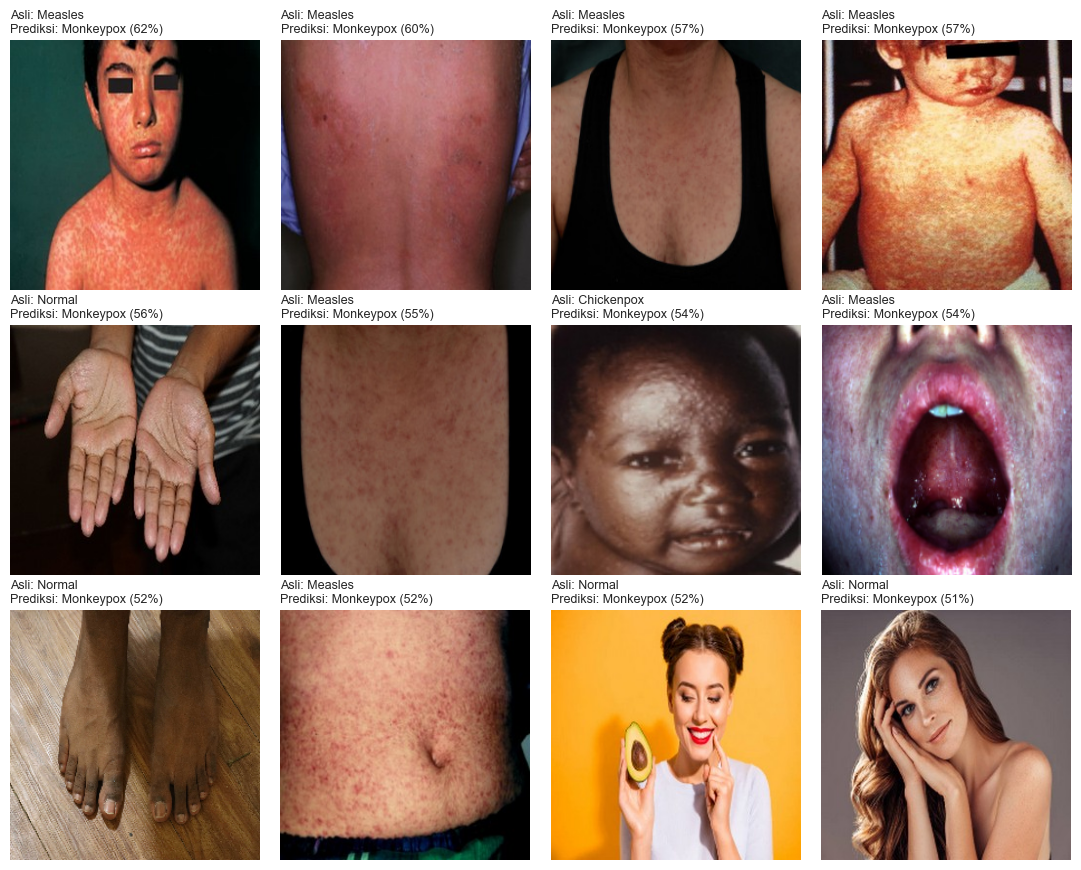

In [20]:
hasil_test = test_df.assign(pred=y_pred, keyakinan=y_prob.max(axis=1)).reset_index(drop=True)
salah = hasil_test[hasil_test["label"] != hasil_test["pred"]].sort_values("keyakinan", ascending=False)
print(f"Salah prediksi: {len(salah)} dari {len(hasil_test)} foto")

jumlah_tampil = min(12, len(salah))
fig, axes = plt.subplots(3, 4, figsize=(11, 8.8))
axes = axes.ravel()
for ax in axes:
    ax.axis("off")
for ax, (_, r) in zip(axes, salah.head(jumlah_tampil).iterrows()):
    ax.imshow(Image.open(r["path"]).convert("RGB"))
    ax.set_title(f"Asli: {r['kelas']}\nPrediksi: {KELAS[r['pred']]} ({r['keyakinan']:.0%})", fontsize=9, loc="left")
plt.tight_layout()
plt.show()

**Temuan:** Model salah pada 48 dari 113 foto. Dua belas kesalahan dengan keyakinan tertinggi semuanya diprediksi Monkeypox, dengan keyakinan hanya 51% sampai 62%. Jadi, model ragu bahkan pada tebakan terkuatnya. Foto Normal berupa potret wanita juga diprediksi Monkeypox, sehingga model tampak belum mempelajari ciri lesi secara spesifik.

### 10.2 Kelas yang sering tertukar

In [21]:
pasangan = pd.DataFrame([{"Label asli": KELAS[a], "Prediksi": KELAS[p], "Jumlah": int(cm[a, p]),
                          "Persen dari kelas asli (%)": round(cm[a, p] / cm[a].sum() * 100, 1)}
                         for a in range(len(KELAS)) for p in range(len(KELAS)) if a != p and cm[a, p] > 0])
tabel(pasangan.sort_values("Jumlah", ascending=False).head(8), presisi=1)

# Kesalahan paling berbahaya: pasien sakit diprediksi Normal
id_normal = label_ke_id["Normal"]
lolos = pd.DataFrame([{"Kelas penyakit": k, "Jumlah foto": int(cm[label_ke_id[k]].sum()),
                       "Diprediksi Normal": int(cm[label_ke_id[k], id_normal])} for k in penyakit])
tabel(lolos)

Label asli,Prediksi,Jumlah,Persen dari kelas asli (%)
Normal,Monkeypox,12,27.3
Measles,Monkeypox,11,84.6
Chickenpox,Monkeypox,8,53.3
Chickenpox,Measles,4,26.7
Normal,Chickenpox,4,9.1
Chickenpox,Normal,3,20.0
Measles,Normal,2,15.4
Monkeypox,Chickenpox,2,4.9


Kelas penyakit,Jumlah foto,Diprediksi Normal
Chickenpox,15,3
Measles,13,2
Monkeypox,41,0


**Temuan:** Pasangan yang paling sering tertukar adalah Normal menjadi Monkeypox (12 foto), Measles menjadi Monkeypox (11 foto), dan Chickenpox menjadi Monkeypox (8 foto). Kesalahan paling berbahaya, yaitu pasien sakit diprediksi Normal, terjadi pada 5 dari 69 foto penyakit (Chickenpox 3, Measles 2, Monkeypox 0).

**Dugaan penyebab kesalahan:**
1. **Data kelas kecil terlalu sedikit**: hanya 71 foto Chickenpox dan 61 foto Measles untuk training.
2. **Model masih *underfitting***: CNN sederhana belum sempat mempelajari perbedaan halus antarruam, dan training berhenti saat loss masih menurun perlahan.
3. **Kemiripan visual**: ruam merah kecil dan bintil pada ketiga penyakit tampak mirip pada resolusi 128 x 128, sehingga detail lesi hilang.
4. **Variasi foto tinggi**: jarak foto, pencahayaan, bagian tubuh, dan latar sangat beragam, sehingga sulit bagi model untuk fokus pada lesi.

Penyebab di atas masih berupa dugaan. Pengecekan lebih lanjut dapat dilakukan dengan Grad-CAM untuk melihat area gambar yang diperhatikan model.

### 10.3 Eksperimen perbaikan model

Hasil model awal menunjukkan *underfitting* dan recall 0 pada Chickenpox serta Measles. Eksperimen ini mengubah satu hal demi satu hal agar dampaknya terlihat. Model awal tetap disimpan sebagai pembanding.

| Varian | Perubahan | Alasan |
|---|---|---|
| V1 | Arsitektur awal, epoch maksimal 60, patience 10 | Training awal berhenti saat loss masih menurun |
| V2 | V1 + 4 blok konvolusi, `BatchNormalization`, Dropout 0,3 | Hidden layer lebih dalam dan training lebih stabil; Dropout dikurangi karena model *underfitting* |
| V3 | V2 + 2 layer konvolusi per blok | Menambah kemampuan mengenali pola tanpa terlalu banyak memperkecil gambar |
| V4 | V2 + resolusi 224 x 224 | Detail ruam kecil lebih terjaga |

Varian terbaik dipilih dari **macro F1-score validasi**, karena metrik ini langsung turun jika ada kelas yang gagal dikenali. Data test hanya dipakai pada varian terpilih. Split data, seed, *class weight*, dan learning rate awal tetap sama.

In [15]:
from sklearn.metrics import f1_score, recall_score

EPOCH_EKSPERIMEN = 60
PATIENCE_STOP = 10
PATIENCE_LR = 4
HASIL_EKSPERIMEN_PATH = PROJECT_DIR / "eksperimen.json"

VARIAN = {
    "V1": {"nama": "Arsitektur awal, training lebih lama", "filter": (32, 64, 128), "conv_per_blok": 1,
           "batch_norm": False, "dropout": 0.5, "ukuran": (128, 128)},
    "V2": {"nama": "4 blok + BatchNorm", "filter": (32, 64, 128, 256), "conv_per_blok": 1,
           "batch_norm": True, "dropout": 0.3, "ukuran": (128, 128)},
    "V3": {"nama": "4 blok, 2 Conv per blok + BatchNorm", "filter": (32, 64, 128, 256), "conv_per_blok": 2,
           "batch_norm": True, "dropout": 0.3, "ukuran": (128, 128)},
    "V4": {"nama": "4 blok + BatchNorm, resolusi 224", "filter": (32, 64, 128, 256), "conv_per_blok": 1,
           "batch_norm": True, "dropout": 0.3, "ukuran": (224, 224)},
}


def bangun_model(cfg, nama):
    m = models.Sequential([
        layers.Input(shape=cfg["ukuran"] + (3,)),
        layers.Rescaling(1.0 / 255),
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.1, seed=SEED),
        layers.RandomZoom(0.1, seed=SEED),
    ], name=nama)
    for jumlah_filter in cfg["filter"]:
        for _ in range(cfg["conv_per_blok"]):
            m.add(layers.Conv2D(jumlah_filter, 3, use_bias=not cfg["batch_norm"]))
            if cfg["batch_norm"]:
                m.add(layers.BatchNormalization())
            m.add(layers.Activation("relu"))
        m.add(layers.MaxPooling2D())
    m.add(layers.GlobalAveragePooling2D())
    m.add(layers.Dense(128, activation="relu"))
    m.add(layers.Dropout(cfg["dropout"], seed=SEED))
    m.add(layers.Dense(len(KELAS), activation="softmax"))
    return m


def buat_ds_varian(data, ukuran, acak=False):
    def baca(path, label):
        gambar = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        return tf.image.resize(gambar, ukuran), label

    ds = tf.data.Dataset.from_tensor_slices((data["path"].values, data["label"].values))
    ds = ds.map(baca, num_parallel_calls=AUTOTUNE).cache()
    if acak:
        ds = ds.shuffle(len(data), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


tabel(pd.DataFrame([{"Varian": k, "Rancangan": v["nama"], "Resolusi": f"{v['ukuran'][0]} x {v['ukuran'][1]}",
                     "Dropout": v["dropout"], "Parameter": f"{bangun_model(v, k).count_params():,}".replace(",", ".")}
                    for k, v in VARIAN.items()]), presisi=1)

Varian,Rancangan,Resolusi,Dropout,Parameter
V1,"Arsitektur awal, training lebih lama",128 x 128,0.5,110.276
V2,4 blok + BatchNorm,128 x 128,0.3,423.268
V3,"4 blok, 2 Conv per blok + BatchNorm",128 x 128,0.3,1.208.548
V4,"4 blok + BatchNorm, resolusi 224",224 x 224,0.3,423.268


**Temuan:** V2 dan V4 memiliki 423.268 parameter, sedangkan V3 memiliki 1.208.548 parameter, jauh lebih banyak daripada arsitektur awal (110.276). Dengan data train hanya 523 foto, risiko *overfitting* perlu dipantau melalui kurva pada bagian berikutnya.

In [16]:
# CELL TRAINING EKSPERIMEN: dijalankan oleh user di GPU
assert gpus, "GPU tidak terdeteksi. Pastikan kernel 'Python (UTS DL)' yang dipakai."

hasil = {}
y_val = val_df["label"].values
for kode, cfg in VARIAN.items():
    print(f"\n===== {kode}: {cfg['nama']} =====")
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    ds_latih = buat_ds_varian(train_df, cfg["ukuran"], acak=True)
    ds_validasi = buat_ds_varian(val_df, cfg["ukuran"])

    m = bangun_model(cfg, kode)
    m.compile(optimizer=optimizers.Adam(learning_rate=LR),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    path_varian = PROJECT_DIR / f"best_{kode}.keras"
    h = m.fit(ds_latih, validation_data=ds_validasi, epochs=EPOCH_EKSPERIMEN, class_weight=class_weight, verbose=2,
              callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE_STOP, restore_best_weights=True),
                         callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=PATIENCE_LR),
                         callbacks.ModelCheckpoint(str(path_varian), monitor="val_loss", save_best_only=True)])

    m = tf.keras.models.load_model(path_varian)
    prediksi_val = m.predict(ds_validasi, verbose=0).argmax(axis=1)
    riw = {k: [float(x) for x in v] for k, v in h.history.items()}
    terbaik_ke = int(np.argmin(riw["val_loss"]))
    hasil[kode] = {"riwayat": riw, "epoch_berjalan": len(riw["val_loss"]), "epoch_terbaik": terbaik_ke + 1,
                   "val_loss": riw["val_loss"][terbaik_ke], "val_accuracy": riw["val_accuracy"][terbaik_ke],
                   "val_macro_f1": float(f1_score(y_val, prediksi_val, average="macro", zero_division=0)),
                   "val_macro_recall": float(recall_score(y_val, prediksi_val, average="macro", zero_division=0))}

HASIL_EKSPERIMEN_PATH.write_text(json.dumps(hasil, indent=2))
print("Eksperimen selesai")


===== V1: Arsitektur awal, training lebih lama =====
Epoch 1/60
17/17 - 13s - loss: 1.4016 - accuracy: 0.2275 - val_loss: 1.3707 - val_accuracy: 0.5179 - lr: 0.0010 - 13s/epoch - 772ms/step
Epoch 2/60
17/17 - 5s - loss: 1.3808 - accuracy: 0.3977 - val_loss: 1.3607 - val_accuracy: 0.4286 - lr: 0.0010 - 5s/epoch - 316ms/step
Epoch 3/60
17/17 - 6s - loss: 1.3522 - accuracy: 0.4379 - val_loss: 1.2660 - val_accuracy: 0.5089 - lr: 0.0010 - 6s/epoch - 334ms/step
Epoch 4/60
17/17 - 6s - loss: 1.2930 - accuracy: 0.5220 - val_loss: 1.2834 - val_accuracy: 0.5000 - lr: 0.0010 - 6s/epoch - 333ms/step
Epoch 5/60
17/17 - 5s - loss: 1.3273 - accuracy: 0.4379 - val_loss: 1.3332 - val_accuracy: 0.3571 - lr: 0.0010 - 5s/epoch - 305ms/step
Epoch 6/60
17/17 - 6s - loss: 1.3039 - accuracy: 0.4168 - val_loss: 1.2781 - val_accuracy: 0.4732 - lr: 0.0010 - 6s/epoch - 337ms/step
Epoch 7/60
17/17 - 5s - loss: 1.2536 - accuracy: 0.4723 - val_loss: 1.2152 - val_accuracy: 0.5268 - lr: 0.0010 - 5s/epoch - 315ms/step

#### Perbandingan pada data validasi

In [17]:
hasil = json.loads(HASIL_EKSPERIMEN_PATH.read_text())
ringkasan = pd.DataFrame([{"Varian": k, "Rancangan": VARIAN[k]["nama"], "Epoch berjalan": v["epoch_berjalan"],
                           "Epoch terbaik": v["epoch_terbaik"], "val_loss": v["val_loss"], "val_accuracy": v["val_accuracy"],
                           "Macro F1 val": v["val_macro_f1"], "Macro recall val": v["val_macro_recall"]}
                          for k, v in hasil.items()]).sort_values("Macro F1 val", ascending=False)
tabel(ringkasan)
VARIAN_TERPILIH = ringkasan.iloc[0]["Varian"]
print("Varian terpilih:", VARIAN_TERPILIH, "-", VARIAN[VARIAN_TERPILIH]["nama"])

Varian,Rancangan,Epoch berjalan,Epoch terbaik,val_loss,val_accuracy,Macro F1 val,Macro recall val
V1,"Arsitektur awal, training lebih lama",52,42,1.008,0.571,0.444,0.457
V2,4 blok + BatchNorm,11,1,1.429,0.134,0.059,0.250
V3,"4 blok, 2 Conv per blok + BatchNorm",11,1,1.445,0.134,0.059,0.250
V4,"4 blok + BatchNorm, resolusi 224",11,1,1.418,0.134,0.059,0.250


Varian terpilih: V1 - Arsitektur awal, training lebih lama


**Temuan:**
- **V1 terpilih** dengan macro F1-score validasi 0,444. Menambah batas epoch saja sudah bermanfaat: training berjalan 52 epoch dan `val_loss` turun dari 1,1838 menjadi 1,0078.
- **V2, V3, dan V4 gagal**, dengan akurasi validasi tepat 13,4% di semua epoch. Nilai ini sama dengan proporsi Chickenpox pada data validasi (15 dari 112), yang menunjukkan model menebak satu kelas saja.
- Hasil V2 sampai V4 **belum dapat menjadi bukti bahwa hidden layer tambahan lebih buruk**. Penyebab yang paling mungkin adalah `BatchNormalization` dengan momentum bawaan 0,99. Rata-rata statistik yang dipakai saat validasi diperbarui sangat lambat, sedangkan training hanya berjalan 187 langkah (17 langkah per epoch selama 11 epoch).

#### Kurva loss dan accuracy tiap varian

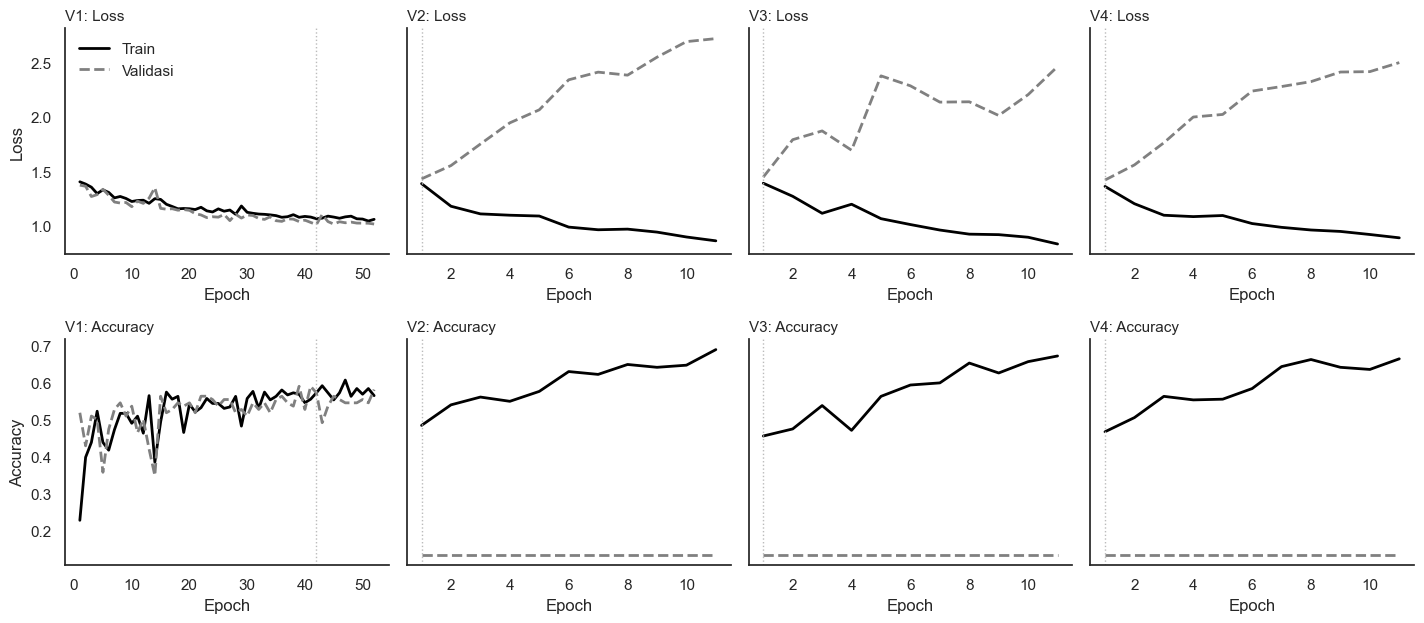

In [18]:
fig, axes = plt.subplots(2, len(hasil), figsize=(3.6 * len(hasil), 6.4), sharey="row", squeeze=False)
for kolom, (kode, v) in enumerate(hasil.items()):
    for baris, (kunci, judul) in enumerate([("loss", "Loss"), ("accuracy", "Accuracy")]):
        ax = axes[baris, kolom]
        r = v["riwayat"]
        e = np.arange(1, len(r[kunci]) + 1)
        ax.plot(e, r[kunci], color="black", linewidth=2, label="Train")
        ax.plot(e, r[f"val_{kunci}"], color="#808080", linewidth=2, linestyle="--", label="Validasi")
        ax.axvline(v["epoch_terbaik"], color="#BBBBBB", linewidth=1, linestyle=":")
        ax.set_title(f"{kode}: {judul}", loc="left", fontsize=11)
        ax.set_xlabel("Epoch")
        if kolom == 0:
            ax.set_ylabel(judul)
axes[0, 0].legend(frameon=False)
plt.tight_layout()
plt.show()

**Temuan:**
- **V1** memiliki kurva train dan validasi yang berimpit (akurasi 57,17% dan 57,14% pada epoch terbaik), sehingga tidak terjadi *overfitting*. Loss train turun dari 1,40 menjadi 1,06 dan akurasi train tertinggi 60,61%, sehingga model masih sedikit *underfitting*.
- **V2 sampai V4** memiliki pola yang berbeda: loss train turun, tetapi loss validasi naik sejak epoch pertama sampai sekitar 2,5, sementara akurasi validasi tidak berubah. Pola tersebut sesuai dengan masalah `BatchNormalization` pada mode validasi. Karena `val_loss` terbaik ada di epoch 1, *early stopping* menghentikan training pada epoch 11.

#### Evaluasi varian terpilih pada data test

Metrik,Model awal,Varian V1
Accuracy,0.575,0.673
Macro F1,0.352,0.583
Recall Chickenpox,0.000,0.400
Recall Measles,0.000,0.385
Recall Monkeypox,0.902,0.683
Recall Normal,0.636,0.841


              precision    recall  f1-score   support

  Chickenpox      0.353     0.400     0.375        15
     Measles      0.556     0.385     0.455        13
   Monkeypox      0.718     0.683     0.700        41
      Normal      0.771     0.841     0.804        44

    accuracy                          0.673       113
   macro avg      0.599     0.577     0.583       113
weighted avg      0.671     0.673     0.669       113



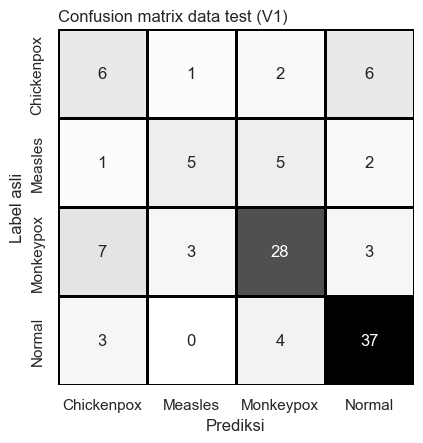

In [19]:
cfg_terpilih = VARIAN[VARIAN_TERPILIH]
model_terpilih = tf.keras.models.load_model(PROJECT_DIR / f"best_{VARIAN_TERPILIH}.keras")
model_awal = tf.keras.models.load_model(MODEL_PATH)
ds_test_terpilih = buat_ds_varian(test_df, cfg_terpilih["ukuran"])
y_test = test_df["label"].values


def ringkas_test(mdl, ds):
    p = mdl.predict(ds, verbose=0).argmax(axis=1)
    rec = recall_score(y_test, p, average=None, labels=np.arange(len(KELAS)), zero_division=0)
    return p, {"Accuracy": float((p == y_test).mean()),
               "Macro F1": float(f1_score(y_test, p, average="macro", zero_division=0)),
               **{f"Recall {k}": float(r) for k, r in zip(KELAS, rec)}}


_, nilai_awal = ringkas_test(model_awal, test_ds)
pred_terpilih, nilai_terpilih = ringkas_test(model_terpilih, ds_test_terpilih)
tabel(pd.DataFrame({"Metrik": list(nilai_awal), "Model awal": list(nilai_awal.values()),
                    f"Varian {VARIAN_TERPILIH}": list(nilai_terpilih.values())}))

print(classification_report(y_test, pred_terpilih, target_names=KELAS, zero_division=0, digits=3))

cm_terpilih = confusion_matrix(y_test, pred_terpilih, labels=np.arange(len(KELAS)))
fig, ax = plt.subplots(figsize=(5.6, 4.6))
sns.heatmap(cm_terpilih, annot=True, fmt="d", cmap="Greys", cbar=False, linewidths=1, linecolor="black",
            xticklabels=KELAS, yticklabels=KELAS, square=True, ax=ax)
ax.set_title(f"Confusion matrix data test ({VARIAN_TERPILIH})", loc="left")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label asli")
plt.tight_layout()
plt.show()

**Temuan:** V1 lebih baik daripada model awal pada data test.

| Metrik | Model awal | V1 | Perubahan |
|---|---|---|---|
| Accuracy | 57,52% | **67,26%** | naik 9,74 poin |
| Macro F1-score | 0,352 | **0,583** | naik 0,231 |
| Recall Chickenpox | 0,000 | **0,400** | naik |
| Recall Measles | 0,000 | **0,385** | naik |
| Recall Normal | 0,636 | **0,841** | naik |
| Recall Monkeypox | 0,902 | 0,683 | turun |

- Model tidak lagi hanya menebak Monkeypox, sehingga recall Monkeypox turun, tetapi precision-nya naik dari 0,544 menjadi 0,718.
- Foto penyakit yang diprediksi Normal naik dari 5 menjadi **11 dari 69 foto** (15,9%), sedangkan salah alarm pada foto Normal turun dari 16 menjadi **7 dari 44 foto** (15,9%). Bagi skrining, kenaikan pasien sakit yang lolos adalah biaya yang perlu diperhatikan.
- Target rancangan **belum tercapai**: tidak ada kelas penyakit dengan recall minimal 0,80, dan macro F1-score 0,583 masih di bawah 0,75.
- Data test hanya 113 foto, sehingga selisih beberapa foto dapat mengubah hasil cukup besar.

### 10.4 Eksperimen lanjutan hidden layer

Pada Bagian 10.3, varian dengan `BatchNormalization` gagal pada data validasi, sehingga pengaruh hidden layer belum dapat dinilai. Eksperimen ini memperbaikinya dengan dua cara: momentum `BatchNormalization` diturunkan dari 0,99 menjadi 0,9, dan disediakan varian hidden layer tambahan **tanpa** `BatchNormalization` sebagai pembanding.

| Varian | Rancangan | Alasan |
|---|---|---|
| W0 | Arsitektur awal (3 blok, Dropout 0,5) | Pembanding dengan aturan training yang sama |
| W1 | 4 blok konvolusi tanpa BatchNorm | Menguji hidden layer tambahan saja |
| W2 | 3 blok, `Dense` 256, Dropout 0,3 | Menguji layer `Dense` lebih lebar karena V1 masih *underfitting* |
| W3 | 4 blok + BatchNorm momentum 0,9 | Mengulang V2 dengan pengaturan yang diperbaiki |
| W4 | 4 blok, 2 Conv per blok + BatchNorm momentum 0,9 | Mengulang V3 dengan pengaturan yang diperbaiki |
| W5 | 4 blok + BatchNorm momentum 0,9, resolusi 224 | Mengulang V4 dengan pengaturan yang diperbaiki |
| W6 | 4 blok tanpa BatchNorm, resolusi 224 | Menguji detail gambar lebih tinggi tanpa BatchNorm |

Semua varian memakai epoch maksimal 100 dan patience 15. Pemilihan tetap memakai **macro F1-score validasi**, dan data test hanya dipakai untuk varian terpilih.

In [33]:
from sklearn.metrics import f1_score, recall_score

EPOCH_LANJUT = 100
PATIENCE_STOP_LANJUT = 15
PATIENCE_LR_LANJUT = 5
HASIL_LANJUT_PATH = PROJECT_DIR / "eksperimen_lanjutan.json"

VARIAN_LANJUT = {
    "W0": {"nama": "Arsitektur awal", "filter": (32, 64, 128), "conv_per_blok": 1,
           "batch_norm": False, "dense": 128, "dropout": 0.5, "ukuran": (128, 128)},
    "W1": {"nama": "4 blok tanpa BatchNorm", "filter": (32, 64, 128, 256), "conv_per_blok": 1,
           "batch_norm": False, "dense": 128, "dropout": 0.3, "ukuran": (128, 128)},
    "W2": {"nama": "3 blok, Dense 256", "filter": (32, 64, 128), "conv_per_blok": 1,
           "batch_norm": False, "dense": 256, "dropout": 0.3, "ukuran": (128, 128)},
    "W3": {"nama": "4 blok + BatchNorm 0,9", "filter": (32, 64, 128, 256), "conv_per_blok": 1,
           "batch_norm": True, "dense": 128, "dropout": 0.3, "ukuran": (128, 128)},
    "W4": {"nama": "4 blok, 2 Conv per blok + BatchNorm 0,9", "filter": (32, 64, 128, 256), "conv_per_blok": 2,
           "batch_norm": True, "dense": 128, "dropout": 0.3, "ukuran": (128, 128)},
    "W5": {"nama": "4 blok + BatchNorm 0,9, resolusi 224", "filter": (32, 64, 128, 256), "conv_per_blok": 1,
           "batch_norm": True, "dense": 128, "dropout": 0.3, "ukuran": (224, 224)},
    "W6": {"nama": "4 blok tanpa BatchNorm, resolusi 224", "filter": (32, 64, 128, 256), "conv_per_blok": 1,
           "batch_norm": False, "dense": 128, "dropout": 0.3, "ukuran": (224, 224)},
}


def bangun_model_lanjut(cfg, nama):
    m = models.Sequential([
        layers.Input(shape=cfg["ukuran"] + (3,)),
        layers.Rescaling(1.0 / 255),
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.1, seed=SEED),
        layers.RandomZoom(0.1, seed=SEED),
    ], name=nama)
    for jumlah_filter in cfg["filter"]:
        for _ in range(cfg["conv_per_blok"]):
            m.add(layers.Conv2D(jumlah_filter, 3, use_bias=not cfg["batch_norm"]))
            if cfg["batch_norm"]:
                m.add(layers.BatchNormalization(momentum=0.9))
            m.add(layers.Activation("relu"))
        m.add(layers.MaxPooling2D())
    m.add(layers.GlobalAveragePooling2D())
    m.add(layers.Dense(cfg["dense"], activation="relu"))
    m.add(layers.Dropout(cfg["dropout"], seed=SEED))
    m.add(layers.Dense(len(KELAS), activation="softmax"))
    return m


def buat_ds_lanjut(data, ukuran, acak=False):
    def baca(path, label):
        gambar = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        return tf.image.resize(gambar, ukuran), label

    ds = tf.data.Dataset.from_tensor_slices((data["path"].values, data["label"].values))
    ds = ds.map(baca, num_parallel_calls=AUTOTUNE).cache()
    if acak:
        ds = ds.shuffle(len(data), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


tabel(pd.DataFrame([{"Varian": k, "Rancangan": v["nama"], "Resolusi": f"{v['ukuran'][0]} x {v['ukuran'][1]}",
                     "Parameter": f"{bangun_model_lanjut(v, k).count_params():,}".replace(",", ".")}
                    for k, v in VARIAN_LANJUT.items()]))

Varian,Rancangan,Resolusi,Parameter
W0,Arsitektur awal,128 x 128,110.276
W1,4 blok tanpa BatchNorm,128 x 128,421.828
W2,"3 blok, Dense 256",128 x 128,127.300
W3,"4 blok + BatchNorm 0,9",128 x 128,423.268
W4,"4 blok, 2 Conv per blok + BatchNorm 0,9",128 x 128,1.208.548
W5,"4 blok + BatchNorm 0,9, resolusi 224",224 x 224,423.268
W6,"4 blok tanpa BatchNorm, resolusi 224",224 x 224,421.828


**Temuan:** Jumlah parameter berkisar dari 110.276 (W0) sampai 1.208.548 (W4). Mengubah resolusi tidak mengubah jumlah parameter, karena `GlobalAveragePooling2D` menghasilkan ukuran output yang sama pada resolusi berapa pun.

In [34]:
# CELL TRAINING EKSPERIMEN LANJUTAN: dijalankan oleh user di GPU
assert gpus, "GPU tidak terdeteksi. Pastikan kernel 'Python (UTS DL)' yang dipakai."

hasil_lanjut = {}
y_val = val_df["label"].values
for kode, cfg in VARIAN_LANJUT.items():
    print(f"\n===== {kode}: {cfg['nama']} =====")
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    ds_latih = buat_ds_lanjut(train_df, cfg["ukuran"], acak=True)
    ds_validasi = buat_ds_lanjut(val_df, cfg["ukuran"])

    m = bangun_model_lanjut(cfg, kode)
    m.compile(optimizer=optimizers.Adam(learning_rate=LR),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    path_varian = PROJECT_DIR / f"best_{kode}.keras"
    h = m.fit(ds_latih, validation_data=ds_validasi, epochs=EPOCH_LANJUT, class_weight=class_weight, verbose=2,
              callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE_STOP_LANJUT, restore_best_weights=True),
                         callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=PATIENCE_LR_LANJUT),
                         callbacks.ModelCheckpoint(str(path_varian), monitor="val_loss", save_best_only=True)])

    m = tf.keras.models.load_model(path_varian)
    prediksi_val = m.predict(ds_validasi, verbose=0).argmax(axis=1)
    riw = {k: [float(x) for x in v] for k, v in h.history.items()}
    terbaik_ke = int(np.argmin(riw["val_loss"]))
    hasil_lanjut[kode] = {"riwayat": riw, "epoch_berjalan": len(riw["val_loss"]), "epoch_terbaik": terbaik_ke + 1,
                          "val_loss": riw["val_loss"][terbaik_ke], "val_accuracy": riw["val_accuracy"][terbaik_ke],
                          "val_macro_f1": float(f1_score(y_val, prediksi_val, average="macro", zero_division=0)),
                          "val_macro_recall": float(recall_score(y_val, prediksi_val, average="macro", zero_division=0))}

HASIL_LANJUT_PATH.write_text(json.dumps(hasil_lanjut, indent=2))
print("Eksperimen lanjutan selesai")


===== W0: Arsitektur awal =====
Epoch 1/100
17/17 - 8s - loss: 1.4015 - accuracy: 0.2314 - val_loss: 1.3710 - val_accuracy: 0.4643 - lr: 0.0010 - 8s/epoch - 466ms/step
Epoch 2/100
17/17 - 4s - loss: 1.3807 - accuracy: 0.3939 - val_loss: 1.3575 - val_accuracy: 0.4911 - lr: 0.0010 - 4s/epoch - 215ms/step
Epoch 3/100
17/17 - 4s - loss: 1.3493 - accuracy: 0.4704 - val_loss: 1.2569 - val_accuracy: 0.5357 - lr: 0.0010 - 4s/epoch - 206ms/step
Epoch 4/100
17/17 - 4s - loss: 1.2988 - accuracy: 0.5086 - val_loss: 1.2581 - val_accuracy: 0.5089 - lr: 0.0010 - 4s/epoch - 214ms/step
Epoch 5/100
17/17 - 3s - loss: 1.3002 - accuracy: 0.4551 - val_loss: 1.2819 - val_accuracy: 0.4286 - lr: 0.0010 - 3s/epoch - 201ms/step
Epoch 6/100
17/17 - 4s - loss: 1.2657 - accuracy: 0.4704 - val_loss: 1.2307 - val_accuracy: 0.4911 - lr: 0.0010 - 4s/epoch - 207ms/step
Epoch 7/100
17/17 - 4s - loss: 1.2506 - accuracy: 0.4685 - val_loss: 1.2239 - val_accuracy: 0.4911 - lr: 0.0010 - 4s/epoch - 233ms/step
Epoch 8/100
17/

#### Perbandingan pada data validasi

In [35]:
hasil_lanjut = json.loads(HASIL_LANJUT_PATH.read_text())
nama_varian = {k: v["nama"] for k, v in VARIAN_LANJUT.items()}

ringkasan_lanjut = pd.DataFrame([{"Varian": k, "Rancangan": nama_varian[k], "Epoch berjalan": v["epoch_berjalan"],
                                  "Epoch terbaik": v["epoch_terbaik"], "val_loss": v["val_loss"], "val_accuracy": v["val_accuracy"],
                                  "Macro F1 val": v["val_macro_f1"], "Macro recall val": v["val_macro_recall"]}
                                 for k, v in hasil_lanjut.items()]).sort_values("Macro F1 val", ascending=False)
tabel(ringkasan_lanjut)
TERPILIH_AKHIR = ringkasan_lanjut.iloc[0]["Varian"]
print("Varian terpilih:", TERPILIH_AKHIR, "-", nama_varian[TERPILIH_AKHIR])

Varian,Rancangan,Epoch berjalan,Epoch terbaik,val_loss,val_accuracy,Macro F1 val,Macro recall val
W5,"4 blok + BatchNorm 0,9, resolusi 224",53,38,0.744,0.688,0.634,0.652
W4,"4 blok, 2 Conv per blok + BatchNorm 0,9",32,17,0.901,0.643,0.596,0.617
W3,"4 blok + BatchNorm 0,9",51,36,0.792,0.661,0.566,0.576
W6,"4 blok tanpa BatchNorm, resolusi 224",47,32,0.928,0.589,0.491,0.505
W1,4 blok tanpa BatchNorm,48,33,0.947,0.580,0.464,0.476
W2,"3 blok, Dense 256",47,32,0.975,0.580,0.453,0.464
W0,Arsitektur awal,57,42,0.991,0.580,0.450,0.463


Varian terpilih: W5 - 4 blok + BatchNorm 0,9, resolusi 224


**Temuan:** **W5 terpilih** dengan macro F1-score validasi 0,634, jauh di atas arsitektur awal W0 (0,450).
- **Dugaan pada Bagian 10.3 terbukti**: setelah momentum `BatchNormalization` diturunkan menjadi 0,9, varian yang sebelumnya gagal kini bekerja. W3 mencapai macro F1-score 0,566, padahal V2 dengan rancangan yang sama hanya 0,059.
- **Menambah hidden layer saja hampir tidak berpengaruh**: W1 (4 blok tanpa BatchNorm) hanya 0,464 dan W2 (`Dense` 256) hanya 0,453, dekat dengan W0.
- **`BatchNormalization` memberi peningkatan terbesar**, dan resolusi 224 menambah peningkatan tersebut (W3 ke W5 naik dari 0,566 menjadi 0,634).
- Hasil W0 (0,450) dekat dengan V1 (0,444), sehingga eksperimen cukup konsisten walau arsitektur yang sama dilatih ulang.

#### Kurva loss dan accuracy tiap varian

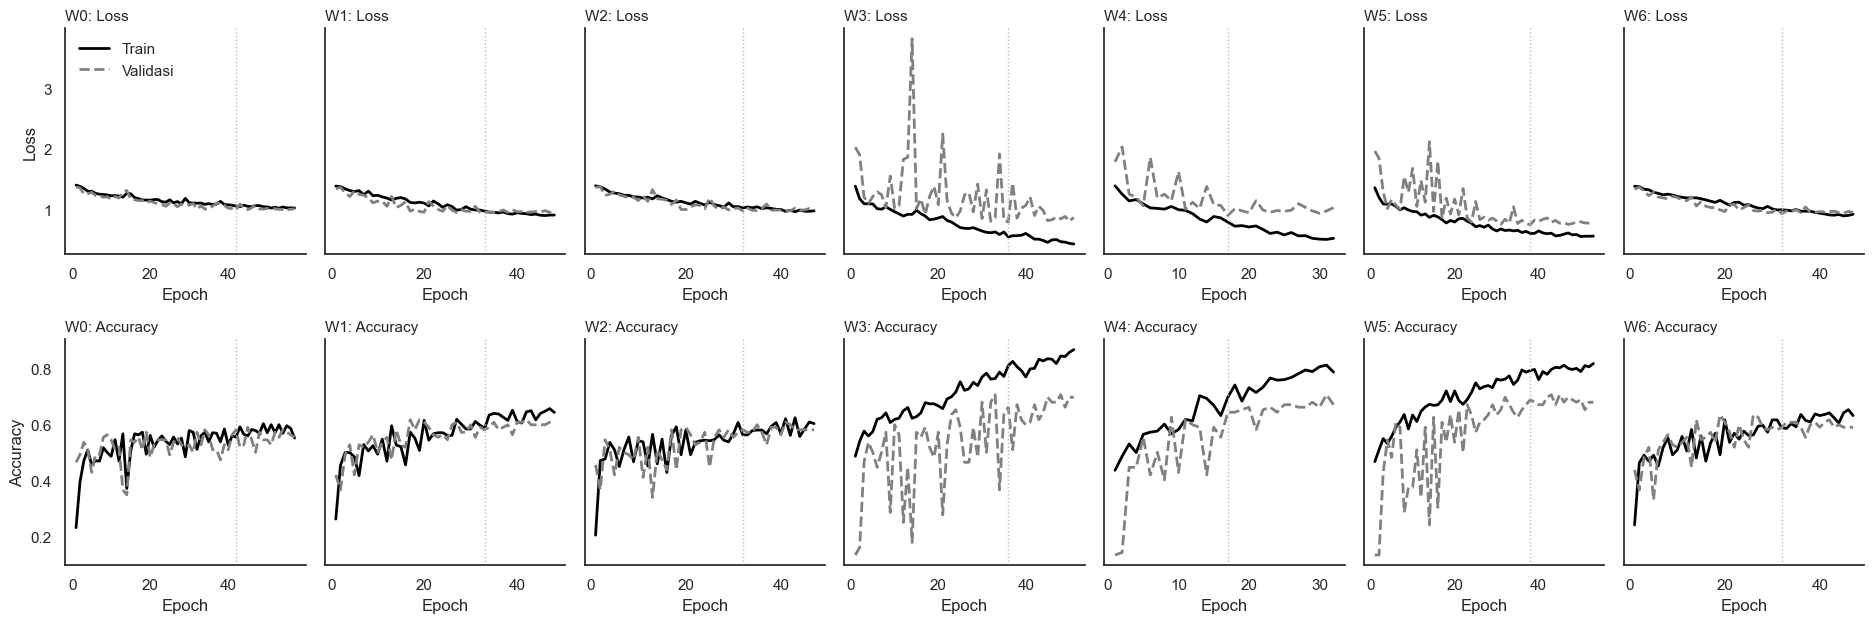

In [36]:
fig, axes = plt.subplots(2, len(hasil_lanjut), figsize=(2.7 * len(hasil_lanjut), 6.4), sharey="row", squeeze=False)
for kolom, (kode, v) in enumerate(hasil_lanjut.items()):
    for baris, (kunci, judul) in enumerate([("loss", "Loss"), ("accuracy", "Accuracy")]):
        ax = axes[baris, kolom]
        r = v["riwayat"]
        e = np.arange(1, len(r[kunci]) + 1)
        ax.plot(e, r[kunci], color="black", linewidth=2, label="Train")
        ax.plot(e, r[f"val_{kunci}"], color="#808080", linewidth=2, linestyle="--", label="Validasi")
        ax.axvline(v["epoch_terbaik"], color="#BBBBBB", linewidth=1, linestyle=":")
        ax.set_title(f"{kode}: {judul}", loc="left", fontsize=11)
        ax.set_xlabel("Epoch")
        if kolom == 0:
            ax.set_ylabel(judul)
axes[0, 0].legend(frameon=False)
plt.tight_layout()
plt.show()

**Temuan:**
- **Tanpa BatchNorm (W0, W1, W2, W6)**: kurva train dan validasi berimpit, tetapi akurasi train hanya sekitar 55% sampai 59% pada epoch terbaik. Model masih *underfitting*.
- **Dengan BatchNorm (W3, W4, W5)**: akurasi train jauh lebih tinggi. Kurva validasi sangat naik turun pada sekitar 20 epoch pertama, lalu mulai stabil setelah learning rate diturunkan.
- **W5** memiliki akurasi train 79,2% dan validasi 68,8% pada epoch terbaik. Selisih sekitar 10 poin ini menunjukkan *overfitting* ringan, tetapi `val_loss` tetap lebih baik daripada semua varian lain (0,744).

#### Evaluasi varian terpilih pada data test

Metrik,Model awal,W5
Accuracy,0.575,0.690
Macro F1,0.352,0.600
Recall Chickenpox,0.000,0.267
Recall Measles,0.000,0.615
Recall Monkeypox,0.902,0.732
Recall Normal,0.636,0.818


              precision    recall  f1-score   support

  Chickenpox      0.333     0.267     0.296        15
     Measles      0.500     0.615     0.552        13
   Monkeypox      0.682     0.732     0.706        41
      Normal      0.878     0.818     0.847        44

    accuracy                          0.690       113
   macro avg      0.598     0.608     0.600       113
weighted avg      0.691     0.690     0.689       113



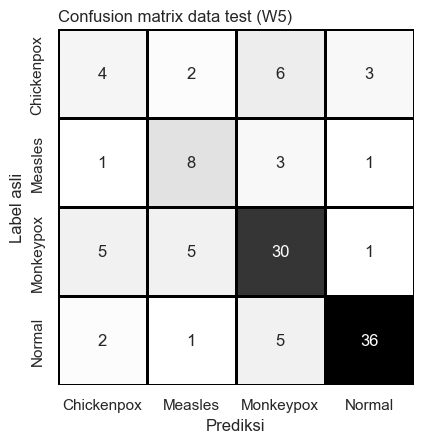

In [37]:
ukuran_akhir = VARIAN_LANJUT[TERPILIH_AKHIR]["ukuran"]
y_test = test_df["label"].values


def nilai_test(path, ukuran):
    mdl = tf.keras.models.load_model(path)
    p = mdl.predict(buat_ds_lanjut(test_df, ukuran), verbose=0).argmax(axis=1)
    rec = recall_score(y_test, p, average=None, labels=np.arange(len(KELAS)), zero_division=0)
    return p, {"Accuracy": float((p == y_test).mean()),
               "Macro F1": float(f1_score(y_test, p, average="macro", zero_division=0)),
               **{f"Recall {k}": float(r) for k, r in zip(KELAS, rec)}}


_, nilai_awal = nilai_test(MODEL_PATH, (128, 128))
pred_akhir, nilai_akhir = nilai_test(PROJECT_DIR / f"best_{TERPILIH_AKHIR}.keras", ukuran_akhir)

tabel(pd.DataFrame({"Metrik": list(nilai_awal), "Model awal": list(nilai_awal.values()),
                    TERPILIH_AKHIR: list(nilai_akhir.values())}))

print(classification_report(y_test, pred_akhir, target_names=KELAS, zero_division=0, digits=3))

cm_akhir = confusion_matrix(y_test, pred_akhir, labels=np.arange(len(KELAS)))
fig, ax = plt.subplots(figsize=(5.6, 4.6))
sns.heatmap(cm_akhir, annot=True, fmt="d", cmap="Greys", cbar=False, linewidths=1, linecolor="black",
            xticklabels=KELAS, yticklabels=KELAS, square=True, ax=ax)
ax.set_title(f"Confusion matrix data test ({TERPILIH_AKHIR})", loc="left")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label asli")
plt.tight_layout()
plt.show()

**Temuan:** W5 menjadi model terbaik pada eksperimen ini.

| Metrik data test | Model awal | V1 | W5 |
|---|---|---|---|
| Accuracy | 57,52% | 67,26% | **69,03%** |
| Macro F1-score | 0,352 | 0,583 | **0,600** |
| Recall Chickenpox | 0,000 | 0,400 | 0,267 |
| Recall Measles | 0,000 | 0,385 | **0,615** |
| Recall Monkeypox | 0,902 | 0,683 | 0,732 |
| Recall Normal | 0,636 | 0,841 | 0,818 |
| Foto penyakit diprediksi Normal (dari 69) | 5 | 11 | **5** |
| Foto Normal menjadi salah alarm (dari 44) | 16 | 7 | 8 |

- Dibandingkan model awal, W5 jauh lebih baik. Foto penyakit yang lolos sebagai Normal juga kembali ke 5 foto, sedangkan salah alarm tetap rendah. Hasil ini paling sesuai dengan kebutuhan skrining.
- Dibandingkan V1, keunggulan W5 pada data test kecil: akurasinya hanya berbeda 2 foto. Keunggulan yang lebih jelas terlihat pada data validasi dan pada jumlah pasien sakit yang lolos.
- **Chickenpox masih menjadi kelas terlemah** (recall 0,267). Dari 15 foto, 6 diprediksi Monkeypox dan 3 diprediksi Normal.
- Target rancangan **belum tercapai**: tidak ada kelas penyakit dengan recall minimal 0,80, dan macro F1-score 0,600 masih di bawah 0,75.
- Macro F1-score test (0,600) sedikit lebih rendah daripada validasi (0,634). Hal ini wajar, karena varian dipilih berdasarkan data validasi.

## 11. Risiko, Batasan & Pengembangan Selanjutnya

### Risiko & batasan

| Aspek | Dampak | Status pada proyek ini |
|---|---|---|
| Data kecil | Hanya 748 foto berbeda, dan data test kelas kecil hanya 13 sampai 15 foto, sehingga hasil per kelas belum stabil | Terjadi |
| Tanpa pre-trained | Model harus mempelajari semua fitur dari data sedikit, sehingga akurasinya terbatas | Terjadi: akurasi test terbaik 69,03% |
| Kemiripan antarpenyakit | Ruam ketiga penyakit mudah tertukar | Terjadi: pada model terbaik, recall Chickenpox 0,267 dan Measles 0,615 |
| Bias latar & watermark | Model dapat belajar dari gaya foto, bukan dari lesi | Belum dapat dipastikan, perlu Grad-CAM |
| Kualitas sumber data | Foto yang sama muncul berulang dan ada satu foto berlabel ganda | Sudah ditangani saat pembersihan |
| Keamanan pasien | Salah prediksi dapat menunda penanganan | **Model bukan pengganti dokter** |
| Privasi | Foto kulit pasien adalah data sensitif | Perlu persetujuan dan pengamanan data jika diterapkan |

### Pengembangan selanjutnya
1. **Transfer learning**: memakai MobileNetV2 atau EfficientNetB0 yang sudah mempelajari fitur visual umum. Langkah ini paling berpotensi meningkatkan hasil pada data kecil.
2. **Menambah data**: terutama foto klinis Measles dan Chickenpox dari sumber yang labelnya terverifikasi tenaga medis.
3. **Menstabilkan training**: menambah regularisasi pada model dengan `BatchNormalization`, mencoba jadwal learning rate yang lebih halus, serta memakai *cross-validation* agar hasil lebih stabil.
4. **Mengurangi bias foto**: memotong gambar pada area lesi, menghapus foto ber-watermark, dan memakai foto Normal yang bergaya klinis.
5. **Memeriksa alasan model**: memakai Grad-CAM untuk memastikan model melihat area lesi.
6. **Deployment bertahap**: setelah kinerja memenuhi target, sistem dapat diuji dahulu pada puskesmas atau telemedisin dengan pengawasan dokter. Foto dengan keyakinan rendah otomatis diarahkan ke tenaga medis.

## 12. Kesimpulan & Rekomendasi untuk Organisasi

### Kesimpulan
- **Problem bisnis** berhasil dirumuskan sebagai skrining awal foto lesi kulit untuk membantu puskesmas dan telemedisin, dengan recall sebagai metrik utama.
- **Pendekatan DL** yang dipilih adalah klasifikasi gambar multi-kelas memakai CNN dari nol, tanpa pre-trained model.
- **Analisis data** menunjukkan bahwa dataset hanya berisi 748 foto berbeda. Pembersihan ini mencegah kebocoran data, sehingga hasil evaluasi lebih jujur.
- **Model awal** mencapai akurasi test 57,52% dan macro F1-score 0,352, serta gagal mengenali Chickenpox dan Measles.
- **Model terbaik (W5)** memakai 4 blok konvolusi, `BatchNormalization` dengan momentum 0,9, dan resolusi 224 x 224. Model ini mencapai **akurasi test 69,03%** dan **macro F1-score 0,600**.
- Eksperimen menunjukkan bahwa `BatchNormalization` dan resolusi lebih tinggi memberi peningkatan lebih besar daripada sekadar menambah hidden layer.
- Target rancangan **belum tercapai**. Kemampuan model membedakan jenis penyakit masih terbatas, terutama pada Chickenpox (recall 0,267).

### Rekomendasi untuk organisasi
1. **Jangan menerapkan model ini untuk triase pasien.** Model terbaik masih melewatkan 11 dari 15 kasus Chickenpox pada data test, sehingga baru layak sebagai prototipe.
2. **Pertahankan pemeriksaan oleh tenaga medis** sebagai jalur utama selama sistem belum tervalidasi.
3. **Kumpulkan data klinis yang lebih baik**, terutama Chickenpox dan Measles, dengan label yang diverifikasi dokter.
4. **Lanjutkan ke transfer learning** sebelum melakukan uji coba di lapangan, lalu gunakan target recall yang sama sebagai syarat kelayakan.
5. **Terapkan ambang keyakinan** ketika sistem sudah layak diuji, sehingga foto yang meragukan langsung ditinjau tenaga medis.

Secara keseluruhan, notebook ini menjawab kedua capaian pembelajaran: permasalahan berbasis data dianalisis dan pendekatan DL ditentukan **(PLO01-CLO02)**, serta model dirancang, dievaluasi, dan diperbaiki secara jujur untuk kebutuhan organisasi **(PLO02-CLO01)**.